# Unsupervised Project

In this project, you will work with a dataset specifying the sale quantities for different products. The rows indicate different products, and the columns will indicate the amount of sales that took place in a given week. You will put to use what you have learned from preprocessing, principal component analysis, kmeans unsupervised clustering, pipelines, and model persistence. 

## Part 0 - Importing the Dataset

The cell below imports the relevant libraries you need and imports the dataset. Run the cell below without modifying it, and then you can proceed.

In [105]:
# Imports needed in this exercise set
import numpy as np
import pandas as pd
import joblib
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.pipeline import Pipeline

# Save the dataset in the same folder as this notebook
sales = pd.read_csv("Sales_Transactions_Dataset_Weekly.csv")

## Part 1 - Exploring the Dataset

Let's start as usual with exploring the dataset.

In [106]:
# Check out the first 5 rows of the dataset
sales.head(5)

,Product_Code,W0,W1,W2,W3,W4,W5,W6,W7,W8,...,Normalized 42,Normalized 43,Normalized 44,Normalized 45,Normalized 46,Normalized 47,Normalized 48,Normalized 49,Normalized 50,Normalized 51
0,P1,11,12,10,8,13,12,14,21,6,...,0.06,0.22,0.28,0.39,0.50,0.00,0.22,0.17,0.11,0.39
1,P2,7,6,3,2,7,1,6,3,3,...,0.20,0.40,0.50,0.10,0.10,0.40,0.50,0.10,0.60,0.00
2,P3,7,11,8,9,10,8,7,13,12,...,0.27,1.00,0.18,0.18,0.36,0.45,1.00,0.45,0.45,0.36
3,P4,12,8,13,5,9,6,9,13,13,...,0.41,0.47,0.06,0.12,0.24,0.35,0.71,0.35,0.29,0.35
4,P5,8,5,13,11,6,7,9,14,9,...,0.27,0.53,0.27,0.60,0.20,0.20,0.13,0.53,0.33,0.40


Not surprisingly, the naming `W0`, `W1`, ..., `W51` represents the 52 weeks of the year, while `P1`, `P2`, ... represents the different products.

Here we can see that the column `Product_Code` should really be the index, as this column represents the observations uniquely, and does not give more information about them.

In [107]:
# Set the index to be the Product_Code column and remove the Product_Code column afterward
sales = sales.set_index("Product_Code")

There are many columns (107). The last part of the columns in the dataset gives the same columns as previously, only normalized.

In [108]:
# Check out the columns with sales.columns
sales.columns

Index(['W0', 'W1', 'W2', 'W3', 'W4', 'W5', 'W6', 'W7', 'W8', 'W9',
       ...
       'Normalized 42', 'Normalized 43', 'Normalized 44', 'Normalized 45',
       'Normalized 46', 'Normalized 47', 'Normalized 48', 'Normalized 49',
       'Normalized 50', 'Normalized 51'],
      dtype='str', length=106)

As you can see, there is an MIN column, a MAX column, and 52 columns giving normalized information. Remove all of these as we only need the 52 columns representing weekly sales.

In [109]:
# Remove MIN, MAX and the Normalized columns
sales = sales.filter(regex=r"^W\d+$")
sales.shape   # deve mostrar 52 colunas


(811, 52)

In [110]:
# Show the first 5 rows again to make sure that everything is as you suspect
sales.head()

,W0,W1,W2,W3,W4,W5,W6,W7,W8,W9,...,W42,W43,W44,W45,W46,W47,W48,W49,W50,W51
Product_Code,,,,,,,,,,,,,,,,,,,,,
P1,11,12,10,8,13,12,14,21,6,14,...,4,7,8,10,12,3,7,6,5,10
P2,7,6,3,2,7,1,6,3,3,3,...,2,4,5,1,1,4,5,1,6,0
P3,7,11,8,9,10,8,7,13,12,6,...,6,14,5,5,7,8,14,8,8,7
P4,12,8,13,5,9,6,9,13,13,11,...,9,10,3,4,6,8,14,8,7,8
P5,8,5,13,11,6,7,9,14,9,9,...,7,11,7,12,6,6,5,11,8,9


In [111]:
# Make sure that none of the columns have missing values
sales.isnull().sum()

W0     0
W1     0
W2     0
W3     0
W4     0
W5     0
W6     0
W7     0
W8     0
W9     0
W10    0
W11    0
W12    0
W13    0
W14    0
W15    0
W16    0
W17    0
W18    0
W19    0
W20    0
W21    0
W22    0
W23    0
W24    0
W25    0
W26    0
W27    0
W28    0
W29    0
W30    0
W31    0
W32    0
W33    0
W34    0
W35    0
W36    0
W37    0
W38    0
W39    0
W40    0
W41    0
W42    0
W43    0
W44    0
W45    0
W46    0
W47    0
W48    0
W49    0
W50    0
W51    0
dtype: int64

In [112]:
# Finally, use .describe() to look at some statistical summaries of the data
sales.describe()

,W0,W1,W2,W3,W4,W5,W6,W7,W8,W9,...,W42,W43,W44,W45,W46,W47,W48,W49,W50,W51
count,811.000000,811.000000,811.000000,811.000000,811.000000,811.000000,811.000000,811.000000,811.000000,811.000000,...,811.000000,811.000000,811.000000,811.000000,811.000000,811.000000,811.000000,811.000000,811.000000,811.000000
mean,8.902589,9.129470,9.389642,9.717633,9.574599,9.466091,9.720099,9.585697,9.784217,9.681874,...,8.394575,8.318126,8.434032,8.556104,8.720099,8.670777,8.674476,8.895191,8.861899,8.889026
std,12.067163,12.564766,13.045073,13.553294,13.095765,12.823195,13.347375,13.049138,13.550237,13.137916,...,11.348777,11.250455,11.223499,11.382041,11.621684,11.435870,11.222996,10.941375,10.492710,9.558011
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000
50%,3.000000,3.000000,3.000000,4.000000,4.000000,3.000000,4.000000,4.000000,4.000000,4.000000,...,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,5.000000,5.000000
75%,12.000000,12.000000,12.000000,13.000000,13.000000,12.500000,13.000000,12.500000,13.000000,13.000000,...,10.000000,11.000000,11.000000,11.000000,11.000000,12.000000,12.000000,12.000000,13.000000,14.000000
max,54.000000,53.000000,56.000000,59.000000,61.000000,52.000000,56.000000,62.000000,63.000000,52.000000,...,52.000000,50.000000,46.000000,46.000000,55.000000,49.000000,50.000000,52.000000,57.000000,73.000000


You should feel free to explore the dataset further if you want to. There are many things you can do, like to create visualizations to understand the data better. Proceed when you feel like you understand the data well.

## Part 2 - PCA for Dimensionality Reduction

The dataset has now only 52 columns left, but this is still quite a lot. We want to reduce the amount of columns to avoid the curse of dimensionality. In this section, we will use the fan favorite algorithm PCA to reduce the number of dimensions from 52 to 5.

Before using a PCA algorithm, it is good practice to scale the data. By doing this, we avoid that the PCA gives higher priority to a column based on having a different scale than the others.

In [113]:
# Initiate a StandardScaler instance

scaler = StandardScaler()

In [114]:
# Scale the sales data by using the .fit_transform method
sales_scaled=scaler.fit_transform(sales)

Now our data is scaled, and we can proceed to using PCA to reduce the number of dimensions.

In [115]:
# Initiate a PCA instance with 5 as the value for n_components
pca=PCA(n_components=5)

In [116]:
# Use .fit_transform to reduce the number of dimensions
sales_pca=pca.fit_transform(sales_scaled)

## Part 3 - Clustering with KMeans

We now have the most important parts of our data represented with only 5 columns. It's time to use a clustering algorithm to cluster the data into cluster groups. We will choose to cluster the data into 3 cluster groups.

In [117]:
# Initiate a KMeans with 3 clusters
kmean=KMeans(n_clusters=3)

In [118]:
# Fit the KMeans model to the processed data
kmean.fit(sales_pca)

c:\Users\Pichau\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=4.
  warnings.warn(


,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",3
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",'auto'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",None
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](3, 5)",

In [119]:
# Get the cluster centers
centers = kmean.cluster_centers_
print(centers)

[[-4.38393244e+00 -1.35227914e-01  1.19740011e-02 -4.28116289e-03
  -2.79012214e-04]
 [ 1.48109967e+01 -4.17365033e-01  3.31282885e-02 -1.87266519e-02
   1.62609623e-02]
 [ 1.58153963e+00  5.99060620e-01 -5.06353722e-02  2.24359119e-02
  -9.54133677e-03]]


In [120]:
# Get the labels of the observations
labels=kmean.labels_
print(labels)

[2 0 2 2 2 0 0 2 2 2 2 0 2 2 1 1 1 1 1 2 2 2 0 1 1 2 1 1 2 1 2 2 2 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 2 2 1 0 1 1 1 1 1 2 1 1 2 1 1 2 1 1 2 1 1 2 1 1 2
 1 1 0 1 1 1 2 2 1 1 1 1 1 1 1 1 2 1 2 2 2 1 1 0 2 2 1 1 2 0 0 2 2 0 2 2 0
 1 1 2 2 2 0 2 1 1 2 2 0 0 2 0 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 2 2 2 2 0
 2 0 0 2 2 2 0 0 2 0 0 2 0 2 0 2 2 2 1 1 1 1 2 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 0 1 2 2 0 2 0 2 0 0 2 0 0 1 2 2 2 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 2 1 2 2 0 2 2 2 2 2 0 0 0 0 0 0 0 0 0 0 0 0 0 2 2 2 0 0 0 0 0 0 0 2 0 0
 0 0 2 0 0 0 0 2 0 0 0 0 2 0 0 0 0 2 0 0 0 0 2 0 0 0 0 2 0 0 0 0 0 0 0 2 2
 2 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 2 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 2 2 2 2 0 0 2 2 2 2 2 2 1
 2 2 0 2 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 2 2 0 2 0 0 2 2 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 2 2 2 2 0 2 2 2 2 2 2 

As you can see, each observation (e.g., product) is grouped into one of three classes with the labels `0`, `1`, or `2`. 

## Part 4 - Create a Pipeline and Persist the Pipeline

We've done several steps to get the clustering of our data. It is now time to put this into a pipeline for simplicity! 

In [121]:
# Create a pipeline for the three steps (Standard Scaler, PCA, and KMeans)
pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA(n_components=5)),
    ("kmeans", KMeans(n_clusters=3, random_state=42))
])

We can now fit our pipeline to the data. Remember to fit the pipeline to the data after we have removed the extra normalized columns, but before scaling anything ourselves. The data used here should have 52 columns.

In [122]:
# Fit the pipeline
pipeline.fit(sales)

c:\Users\Pichau\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=4.
  warnings.warn(


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('pca', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](52,)","['W0','W1','W2',...,'W49','W50','W51']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,52
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


We can again get for example the cluster labels of the observations. Just remember to access the KMeans algorithm from the pipeline first.

In [123]:
# Get the labels
pipeline_labels = pipeline.named_steps["kmeans"].labels_
print(pipeline_labels)

[0 2 0 0 0 2 2 0 0 0 0 2 0 0 1 1 1 1 1 0 0 0 2 1 1 0 1 1 0 1 0 0 0 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 0 0 1 2 1 1 1 1 1 0 1 1 0 1 1 0 1 1 0 1 1 0 1 1 0
 1 1 2 1 1 1 0 0 1 1 1 1 1 1 1 1 0 1 0 0 0 1 1 2 0 0 1 1 0 2 2 0 0 2 0 0 2
 1 1 0 0 0 2 0 1 1 0 0 2 2 0 2 2 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 0 0 0 0 2
 0 2 2 0 0 0 2 2 0 2 2 0 2 0 2 0 0 0 1 1 1 1 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 2 1 0 0 2 0 2 0 2 2 0 2 2 1 0 0 0 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 0 1 0 0 2 0 0 0 0 0 2 2 2 2 2 2 2 2 2 2 2 2 2 0 0 0 2 2 2 2 2 2 2 0 2 2
 2 2 0 2 2 2 2 0 2 2 2 2 0 2 2 2 2 0 2 2 2 2 0 2 2 2 2 0 2 2 2 2 2 2 2 0 0
 0 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 0 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 0 0 0 0 2 2 0 0 0 0 0 0 1
 0 0 2 0 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 0 0 2 0 2 2 0 0 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 0 0 0 0 2 0 0 0 0 0 0 

Finally, we can persist the whole pipeline to a file by using joblib. This is super convenient as the pipeline bundles up most of what is being done to the data.

In [124]:
# Persist the pipeline as a joblib model
# Persist the pipeline as a joblib model
joblib.dump(pipeline, "sales_clustering_pipeline.joblib")

['sales_clustering_pipeline.joblib']

When a new observation arrive (e.g., a new product that has been on the market for 52 weeks), then you can load the pipeline and use the `.predict()` method to predict the label of the new observation. Which cluster this belongs to can help you to understand how to market the product, or which products should be given as <i>related products</i> on a website.

## Part 5 - Model Validation, Visualization, and Business Insights

In this final section, we evaluate the quality of our dimensionality reduction and clustering choices, visualize the resulting product segments, and test production inference using the persisted pipeline.

### 5.1 PCA Explained Variance Analysis
Before settling on 5 components, let's check how much of the original variance across the 52 weeks is preserved by this dimensionality reduction.

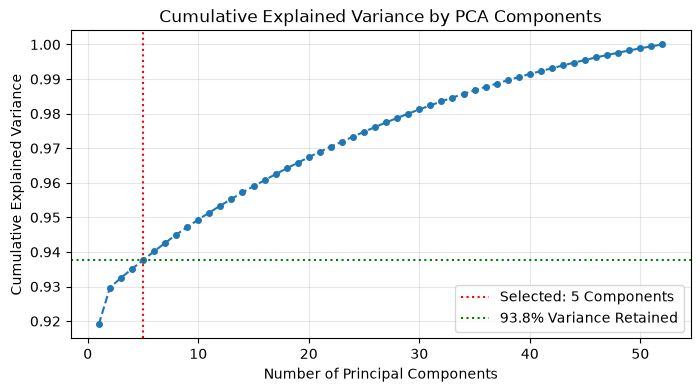

In [125]:
import matplotlib.pyplot as plt

# Fit PCA with all 52 components to inspect cumulative explained variance
pca_full = PCA().fit(sales_scaled)
cum_variance = np.cumsum(pca_full.explained_variance_ratio_)

plt.figure(figsize=(8, 4))
plt.plot(range(1, 53), cum_variance, marker='o', linestyle='--', markersize=4)
plt.axvline(x=5, color='r', linestyle=':', label='Selected: 5 Components')
plt.axhline(y=cum_variance[4], color='g', linestyle=':', label=f'{cum_variance[4]*100:.1f}% Variance Retained')
plt.title('Cumulative Explained Variance by PCA Components')
plt.xlabel('Number of Principal Components')
plt.ylabel('Cumulative Explained Variance')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

### 5.2 Validating the Number of Clusters (Elbow Method & Silhouette Score)
Let's evaluate values of $k$ from 2 to 10 using Inertia (Elbow Method) and Silhouette Score to assess cluster cohesion and separation.

c:\Users\Pichau\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=4.
  warnings.warn(
c:\Users\Pichau\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=4.
  warnings.warn(
c:\Users\Pichau\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=4.
  warnings.warn(
c:\Users\Pichau\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Wi

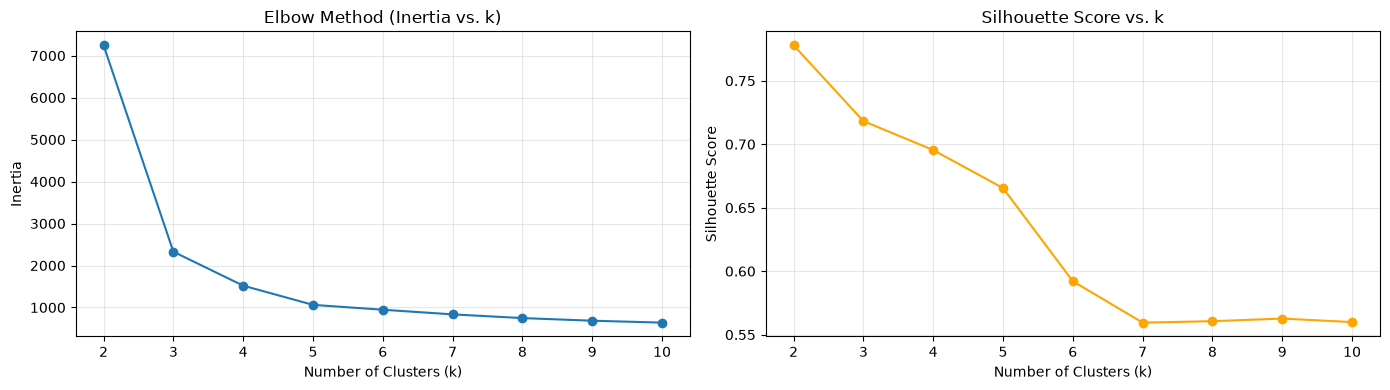

In [126]:
from sklearn.metrics import silhouette_score

inertias = []
silhouettes = []
k_range = range(2, 11)

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    preds = km.fit_predict(sales_pca)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(sales_pca, preds))

fig, ax = plt.subplots(1, 2, figsize=(14, 4))

ax[0].plot(k_range, inertias, marker='o')
ax[0].set_title('Elbow Method (Inertia vs. k)')
ax[0].set_xlabel('Number of Clusters (k)')
ax[0].set_ylabel('Inertia')
ax[0].grid(True, alpha=0.3)

ax[1].plot(k_range, silhouettes, marker='o', color='orange')
ax[1].set_title('Silhouette Score vs. k')
ax[1].set_xlabel('Number of Clusters (k)')
ax[1].set_ylabel('Silhouette Score')
ax[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### 5.3 Visualizing Clusters in 2D PCA Space
Projecting the observations onto the first two principal components (`PC1` and `PC2`) allows us to visually inspect the separation between the 3 product clusters and their centroids.

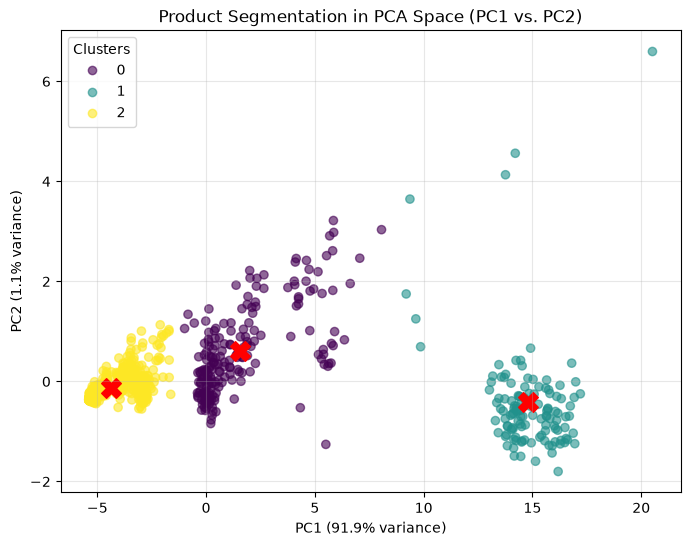

In [127]:
plt.figure(figsize=(8, 6))
scatter = plt.scatter(sales_pca[:, 0], sales_pca[:, 1], c=pipeline_labels, cmap='viridis', alpha=0.6)
plt.scatter(centers[:, 0], centers[:, 1], c='red', marker='X', s=200, label='Centroids')
plt.title('Product Segmentation in PCA Space (PC1 vs. PC2)')
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)')
plt.legend(*scatter.legend_elements(), title="Clusters")
plt.grid(True, alpha=0.3)
plt.show()

### 5.4 Cluster Profiling & Business Interpretation
To translate these mathematical clusters into actionable business insights, let's compute the average weekly sales trajectory for each group across all 52 weeks.

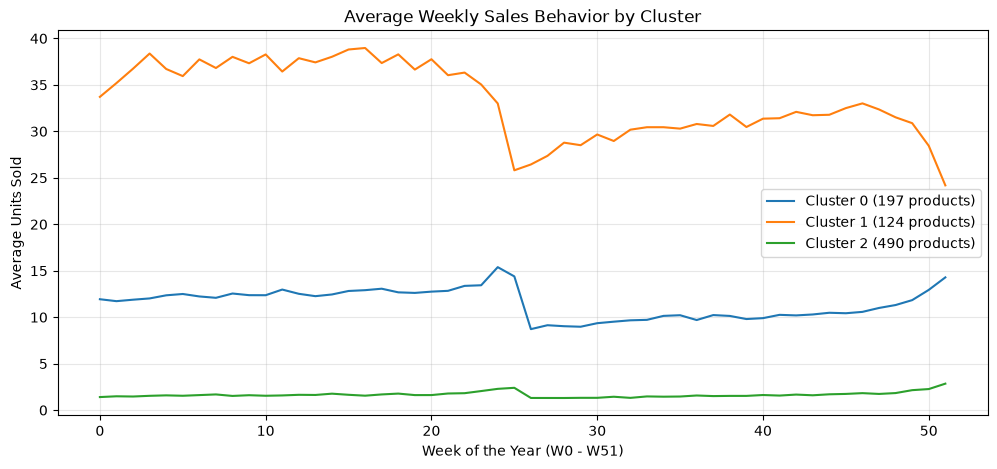

In [128]:
sales_clustered = sales.copy()
sales_clustered['Cluster'] = pipeline_labels

# Compute mean weekly sales per cluster
cluster_profiles = sales_clustered.groupby('Cluster').mean()

plt.figure(figsize=(12, 5))
for cluster_id in cluster_profiles.index:
    count = (pipeline_labels == cluster_id).sum()
    plt.plot(range(52), cluster_profiles.loc[cluster_id], label=f'Cluster {cluster_id} ({count} products)')

plt.title('Average Weekly Sales Behavior by Cluster')
plt.xlabel('Week of the Year (W0 - W51)')
plt.ylabel('Average Units Sold')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

### 5.5 Production Inference Test
Finally, let's verify that our persisted `.joblib` file can be loaded from disk and used directly to predict the segment of a new incoming product.

In [129]:
# Load the persisted pipeline from disk
loaded_pipeline = joblib.load("sales_clustering_pipeline.joblib")

# Simulate a new product arrival (1 row with 52 weekly features)
sample_product = sales.iloc[[0]]
predicted_cluster = loaded_pipeline.predict(sample_product)

print(f"Product '{sample_product.index[0]}' assigned to Cluster: {predicted_cluster[0]}")

Product 'P1' assigned to Cluster: 0
